In [1]:
# Step P1: Import needed NRPy+ core modules:
from __future__ import annotations
from outputC import lhrh,outputC,outCfunction  # NRPy+: Core C code output module
import NRPy_param_funcs as par   # NRPy+: Parameter interface
import sympy as sp               # SymPy: The Python computer algebra package upon which NRPy+ depends
import finite_difference as fin  # NRPy+: Finite difference C code generation module
import indexedexp as ixp         # NRPy+: Symbolic indexed expression (e.g., tensors, vectors, etc.) support
import reference_metric as rfm   # NRPy+: Reference metric support
import deprecated_reference_metric as evil_rfm  # NRPy+: PLEASE DON'T USE.
import cmdline_helper as cmd     # NRPy+: Multi-platform Python command-line interface
import shutil, os, sys           # Standard Python modules for multiplatform OS-level functions
import grid as gri
from pathlib import Path

In [2]:
from nrpytutorial.dirtree import make_dir_node, make_file_node
from nrpytutorial.dirtree import Dirtree

def make_bssn_dirtree(root: str, codes: str, output: str) -> Dirtree:
    dirtree = Dirtree()
    
    root, codes, output = map(make_dir_node, (root, codes, output))
    
    dirtree.set_root(root)
    dirtree.add_node(codes, 'root', 'codes')
    dirtree.add_node(output, 'codes', 'output')    
    
    return dirtree

def create_dirtree_nodes(bssn_dirtree: Dirtree, *node_keys):
    bssn_dirtree.create_root()
    node_keys = (k for k in node_keys if k != 'root')
    for node_key in node_keys:
        bssn_dirtree.create_node(node_key)

In [3]:
bssn_dirtree = make_bssn_dirtree('bssn', 'codes', 'output')
create_dirtree_nodes(bssn_dirtree, 'codes', 'output')

In [4]:
from nrpytutorial.coordinate_systems import build_spherical_coord_system
coord_system = build_spherical_coord_system(32)

In [5]:
from nrpytutorial.numerical_grids import NumericalGrid

numerical_grid_builder = NumericalGrid.get_builder()
numerical_grid_builder.set_spatial_dimensions(3)
numerical_grid_builder.set_coord_system(coord_system)
numerical_grid_builder.set_points_count(30000)
numerical_grid_builder.set_infinity(coord_system.domain_size*1.1)
numerical_grid = numerical_grid_builder.build()

In [6]:
from nrpytutorial.integration_methods import make_integration_method, IntegrationMethodVariant
from nrpytutorial.ccode_rendering import CfloatPrecision
integration_method = make_integration_method(IntegrationMethodVariant.RK4, 0.5, 4, CfloatPrecision.DOUBLE)

In [7]:
import MoLtimestepping.C_Code_Generation as MoL
from MoLtimestepping.RK_Butcher_Table_Dictionary import Butcher_dict
from nrpytutorial.ccode_rendering import CprototypeFactory, CparameterFactory

def make_rktimestepping_home(dirtree: Dirtree):
    moltimestepping_node = make_dir_node('MoLtimestepping')
    dirtree.add_node(moltimestepping_node, 'codes', 'moltimestepping')
    dirtree.create_node('moltimestepping')
    return

def make_rktimestepping_code(dirtree: Dirtree, integration_method: IntegrationMethod):
    rk_order = integration_method.variant.get_attrs().order
    rk_method = integration_method.variant.as_string()
    
    cparmater_factory = CparameterFactory()
    cprototype_factory = CprototypeFactory(cparmater_factory)
    
    ricci_eval = cprototype_factory.create_ricci_eval()
    rhs_eval = cprototype_factory.create_rhs_eval()
    rhs_string = [ricci_eval, rhs_eval]
    rhs_string = "\n".join([p.as_string() for p in rhs_string])

    apply_bcs_curvilinear = cprototype_factory.create_apply_bcs_curvilinear()
    enforce_detgammahat_constraint = cprototype_factory.create_enforce_detgammahat_constraint()
    post_rhs_string = [apply_bcs_curvilinear, enforce_detgammahat_constraint]
    post_rhs_string = "\n".join([p.as_string() for p in post_rhs_string])
    
    home = dirtree.get_node_path('moltimestepping')
    MoL.MoL_C_Code_Generation(
        rk_method,
        RHS_string=rhs_string,
        post_RHS_string=post_rhs_string,
        outdir=str(home),
        )

make_rktimestepping_home(bssn_dirtree)
make_rktimestepping_code(bssn_dirtree, integration_method)

In [8]:
par.set_parval_from_str("reference_metric::CoordSystem", coord_system.kind.as_string())
rfm.reference_metric() # Create ReU, ReDD needed for rescaling B-L initial data, generating BSSN RHSs, etc.

In [9]:
par.set_parval_from_str("finite_difference::FD_CENTDERIVS_ORDER", integration_method.fd_order)

In [10]:
def make_simd_headers(src: Path, dst: Dirtree):
    simd_node = make_dir_node('SIMD')
    dst.add_node(simd_node, 'codes', 'simds')
    dst.create_node('simds')
    
    header_node = make_file_node('SIMD_intrinsics.h')
    dst.add_node(header_node, 'simds', 'simd_header')
    dst.create_node('simd_header')
    
    header = dst.get_node_path('simd_header')
    header.write_text(src.read_text())
    return

make_simd_headers(Path('SIMD/SIMD_intrinsics.h'), bssn_dirtree)

In [11]:
par.set_parval_from_str("indexedexp::symmetry_axes","12")

In [12]:
import deprecated_reference_metric as evil_rfm
def make_find_timestep_header(dirtree: Dirtree):
    node = make_file_node('find_timestep.h')
    dirtree.add_node(node, 'codes', 'find_timestep_header')
    dirtree.create_node('find_timestep_header')
    
    path = dirtree.get_node_path('find_timestep_header')
    evil_rfm.out_timestep_func_to_file(str(path))

make_find_timestep_header(bssn_dirtree)

In [13]:
# Step 2.a: Import necessary Python and NRPy+ modulesg
import ScalarField.ScalarField_InitialData as sfid
from nrpytutorial.pulse import build_gaussian_pulse

def make_scalar_field_init_data(dirtree: Dirtree, numerical_grid: NumericalGrid, pulse: PulseParameters):
    sfid_node = make_file_node("SFID.txt")
    dirtree.add_node(sfid_node, 'output', 'sfidtxt')
    dirtree.create_node('sfidtxt')
    
    outputfilename = dirtree.get_node_path('sfidtxt')
    outputfilename = str(outputfilename)
      
    sfid.ScalarField_InitialData(outputfilename,
                                 pulse.profile.as_string(),
                                 pulse.amplitude,
                                 pulse.center,
                                 pulse.width,
                                 numerical_grid.points_count.radial,
                                 numerical_grid.infinity.radial)
    
    ccodesdir = dirtree.get_node_path('codes')
    ccodesdir = str(ccodesdir)
    sfid.NRPy_param_funcs_register_C_functions_and_NRPy_basic_defines(Ccodesdir=ccodesdir)

pulse = build_gaussian_pulse(0.4, 0, 1)
make_scalar_field_init_data(bssn_dirtree, numerical_grid, pulse)

Generated the ADM initial data for the gravitational collapse 
of a massless scalar field in Spherical coordinates.

Type of initial condition: Scalar field: "Gaussian" Shell
                         ADM quantities: Time-symmetric
                        Lapse condition: Pre-collapsed
Parameters: amplitude         = 0.4,
            center            = 0,
            width             = 1,
            domain size       = 35.2,
            number of points  = 30000,
            Initial data file = bssn/codes/output/SFID.txt.

Output C function ID_scalarfield_ADM_quantities() to file bssn/codes/ID_scalarfield_ADM_quantities.h
Output C function ID_scalarfield_spherical() to file bssn/codes/ID_scalarfield_spherical.h
Output C function ID_scalarfield_xx0xx1xx2_to_BSSN_xx0xx1xx2() to file bssn/codes/ID_scalarfield_xx0xx1xx2_to_BSSN_xx0xx1xx2.h
Output C function ID_scalarfield() to file bssn/codes/ID_scalarfield.h


In [14]:
import BSSN.ADM_Numerical_Spherical_or_Cartesian_to_BSSNCurvilinear as AtoBnum

ccodesdir = str(bssn_dirtree.get_node_path('codes'))
AtoBnum.Convert_Spherical_or_Cartesian_ADM_to_BSSN_curvilinear(
    coord_system.kind.as_string(),
    "ID_scalarfield_ADM_quantities",
    Ccodesdir=ccodesdir,
    loopopts=""
)

Output C function ID_BSSN_lambdas() to file bssn/codes/ID_BSSN_lambdas.h
Output C function ID_ADM_xx0xx1xx2_to_BSSN_xx0xx1xx2__ALL_BUT_LAMBDAs() to file bssn/codes/ID_ADM_xx0xx1xx2_to_BSSN_xx0xx1xx2__ALL_BUT_LAMBDAs.h
Output C function ID_BSSN__ALL_BUT_LAMBDAs() to file bssn/codes/ID_BSSN__ALL_BUT_LAMBDAs.h


In [15]:
from nrpytutorial.foliation_conditions import FoliationCondition, LapseCondition, ShiftCondition
foliation_condition_builder = FoliationCondition.get_builder()
foliation_condition_builder.set_lapse_condition(LapseCondition.ONE_PLUS_LOG)
foliation_condition_builder.set_shift_condition(ShiftCondition.GAMMA_DRIVING)
foliation_condition = foliation_condition_builder.build()

In [16]:
import BSSN.BSSN_RHSs as rhs
import BSSN.BSSN_gauge_RHSs as gaugerhs

In [17]:
from nrpytutorial.dirtree import DirtreeNodeKind
bssn_dirtree.build_node(DirtreeNodeKind.DIR, 'rfm_files', 'codes', 'rfm_files')

In [18]:
par.set_parval_from_str("reference_metric::enable_rfm_precompute","True")
par.set_parval_from_str("reference_metric::rfm_precompute_Ccode_outdir",bssn_dirtree.get_node_str('rfm_files'))

In [19]:
# Evaluate BSSN + BSSN gauge RHSs with rfm_precompute enabled:
import BSSN.BSSN_quantities as Bq
par.set_parval_from_str("BSSN.BSSN_quantities::LeaveRicciSymbolic","True")

rhs.BSSN_RHSs()

# Evaluate the Scalar Field RHSs
import ScalarField.ScalarField_RHSs as sfrhs
sfrhs.ScalarField_RHSs()

# Compute ScalarField T^{\mu\nu}
# Compute the scalar field energy-momentum tensor
import ScalarField.ScalarField_Tmunu as sfTmunu
sfTmunu.ScalarField_Tmunu()
T4UU = sfTmunu.T4UU

import BSSN.BSSN_stress_energy_source_terms as Bsest
Bsest.BSSN_source_terms_for_BSSN_RHSs(T4UU)
rhs.trK_rhs += Bsest.sourceterm_trK_rhs
for i in range(numerical_grid.spatial_dimensions):
    # Needed for Gamma-driving shift RHSs:
    rhs.Lambdabar_rhsU[i] += Bsest.sourceterm_Lambdabar_rhsU[i]
    # Needed for BSSN RHSs:
    rhs.lambda_rhsU[i]    += Bsest.sourceterm_lambda_rhsU[i]
    for j in range(numerical_grid.spatial_dimensions):
        rhs.a_rhsDD[i][j] += Bsest.sourceterm_a_rhsDD[i][j]

gaugerhs.BSSN_gauge_RHSs()

# We use betaU as our upwinding control vector:
Bq.BSSN_basic_tensors()
betaU = Bq.betaU

import BSSN.Enforce_Detgammahat_Constraint as EGC
enforce_detg_constraint_symb_expressions = EGC.Enforce_Detgammahat_Constraint_symb_expressions()

# Next compute Ricci tensor
par.set_parval_from_str("BSSN.BSSN_quantities::LeaveRicciSymbolic","False")
Bq.RicciBar__gammabarDD_dHatD__DGammaUDD__DGammaU()

# Now register the Hamiltonian as a gridfunction.
H = gri.register_gridfunctions("AUX","H")

# Then define the Hamiltonian constraint and output the optimized C code.
import BSSN.BSSN_constraints as bssncon
bssncon.BSSN_constraints(add_T4UUmunu_source_terms=False)
Bsest.BSSN_source_terms_for_BSSN_constraints(T4UU)
bssncon.H += Bsest.sourceterm_H

# Add Kreiss-Oliger dissipation
diss_strength = par.Cparameters("REAL","ScalarFieldCollapse",["diss_strength"],0.1)

alpha_dKOD   = ixp.declarerank1("alpha_dKOD")
cf_dKOD      = ixp.declarerank1("cf_dKOD")
trK_dKOD     = ixp.declarerank1("trK_dKOD")
sf_dKOD      = ixp.declarerank1("sf_dKOD")
sfM_dKOD     = ixp.declarerank1("sfM_dKOD")
betU_dKOD    = ixp.declarerank2("betU_dKOD","nosym")
vetU_dKOD    = ixp.declarerank2("vetU_dKOD","nosym")
lambdaU_dKOD = ixp.declarerank2("lambdaU_dKOD","nosym")
aDD_dKOD     = ixp.declarerank3("aDD_dKOD","sym01")
hDD_dKOD     = ixp.declarerank3("hDD_dKOD","sym01")

for k in range(numerical_grid.spatial_dimensions):
    gaugerhs.alpha_rhs += diss_strength*alpha_dKOD[k]*rfm.ReU[k]
    rhs.cf_rhs         += diss_strength*   cf_dKOD[k]*rfm.ReU[k]
    rhs.trK_rhs        += diss_strength*  trK_dKOD[k]*rfm.ReU[k]
    sfrhs.sf_rhs       += diss_strength*   sf_dKOD[k]*rfm.ReU[k]
    sfrhs.sfM_rhs      += diss_strength*  sfM_dKOD[k]*rfm.ReU[k]
    for i in range(numerical_grid.spatial_dimensions):
        if "2ndOrder" in foliation_condition.shift.as_string():
            gaugerhs.bet_rhsU[i] += diss_strength*   betU_dKOD[i][k]*rfm.ReU[k]
        gaugerhs.vet_rhsU[i]     += diss_strength*   vetU_dKOD[i][k]*rfm.ReU[k]
        rhs.lambda_rhsU[i]       += diss_strength*lambdaU_dKOD[i][k]*rfm.ReU[k]
        for j in range(numerical_grid.spatial_dimensions):
            rhs.a_rhsDD[i][j] += diss_strength*aDD_dKOD[i][j][k]*rfm.ReU[k]
            rhs.h_rhsDD[i][j] += diss_strength*hDD_dKOD[i][j][k]*rfm.ReU[k]

# Now that we are finished with all the rfm hatted
#           quantities in generic precomputed functional
#           form, let's restore them to their closed-
#           form expressions.
par.set_parval_from_str("reference_metric::enable_rfm_precompute","False") # Reset to False to disable rfm_precompute.
rfm.ref_metric__hatted_quantities()

print("(BENCH) Finished BSSN symbolic expressions")

(BENCH) Finished BSSN symbolic expressions


In [20]:
def BSSN_plus_ScalarField_RHSs(dirtree: Dirtree, numerical_grid: NumericalGrid):
    print("Generating C code for BSSN RHSs in "+par.parval_from_str("reference_metric::CoordSystem")+" coordinates.")

    # Construct the left-hand sides and right-hand-side expressions for all BSSN RHSs
    lhs_names = [        "alpha",       "cf",       "trK",         "sf",         "sfM"   ]
    rhs_exprs = [gaugerhs.alpha_rhs, rhs.cf_rhs, rhs.trK_rhs, sfrhs.sf_rhs, sfrhs.sfM_rhs]
    for i in range(numerical_grid.spatial_dimensions):
        lhs_names.append(        "betU"+str(i))
        rhs_exprs.append(gaugerhs.bet_rhsU[i])
        lhs_names.append(   "lambdaU"+str(i))
        rhs_exprs.append(rhs.lambda_rhsU[i])
        lhs_names.append(        "vetU"+str(i))
        rhs_exprs.append(gaugerhs.vet_rhsU[i])
        for j in range(i,numerical_grid.spatial_dimensions):
            lhs_names.append(   "aDD"+str(i)+str(j))
            rhs_exprs.append(rhs.a_rhsDD[i][j])
            lhs_names.append(   "hDD"+str(i)+str(j))
            rhs_exprs.append(rhs.h_rhsDD[i][j])

    # Sort the lhss list alphabetically, and rhss to match.
    #   This ensures the RHSs are evaluated in the same order
    #   they're allocated in memory:
    lhs_names,rhs_exprs = [list(x) for x in zip(*sorted(zip(lhs_names,rhs_exprs), key=lambda pair: pair[0]))]

    # Declare the list of lhrh's
    BSSN_evol_rhss = []
    for var in range(len(lhs_names)):
        BSSN_evol_rhss.append(lhrh(lhs=gri.gfaccess("rhs_gfs",lhs_names[var]),rhs=rhs_exprs[var]))

    # Set up the C function for the BSSN RHSs
    desc="Evaluate the BSSN RHSs"
    name="rhs_eval"
    
    dirtree.build_node(DirtreeNodeKind.FILE, f"{name}.h", 'codes', f'{name}_header')
    outfile = dirtree.get_node_str(f'{name}_header')
    outCfunction(
        outfile  = outfile, desc=desc, name=name,
        params   = """rfm_struct *restrict rfmstruct,const paramstruct *restrict params,
                      const REAL *restrict auxevol_gfs,const REAL *restrict in_gfs,REAL *restrict rhs_gfs""",
        body     = fin.FD_outputC("returnstring",BSSN_evol_rhss, params="outCverbose=False,enable_SIMD=True",
                                  upwindcontrolvec=betaU),
        loopopts = "InteriorPoints,enable_SIMD,enable_rfm_precompute")
    
    print("(BENCH) Finished BSSN_RHS C codegen")

BSSN_plus_ScalarField_RHSs(bssn_dirtree, numerical_grid)

Generating C code for BSSN RHSs in Spherical coordinates.
Output C function rhs_eval() to file bssn/codes/rhs_eval.h
(BENCH) Finished BSSN_RHS C codegen


In [21]:
def Ricci(dirtree: Dirtree):
    print("Generating C code for Ricci tensor in "+par.parval_from_str("reference_metric::CoordSystem")+" coordinates.")
    desc="Evaluate the Ricci tensor"
    name="Ricci_eval"
    
    dirtree.build_node(DirtreeNodeKind.FILE, f"{name}.h", 'codes', f'{name}_header')
    outfile = dirtree.get_node_str(f'{name}_header')
    outCfunction(
        outfile  = outfile, desc=desc, name=name,
        params   = """rfm_struct *restrict rfmstruct,const paramstruct *restrict params,
                      const REAL *restrict in_gfs,REAL *restrict auxevol_gfs""",
        body     = fin.FD_outputC("returnstring",
                                  [lhrh(lhs=gri.gfaccess("auxevol_gfs","RbarDD00"),rhs=Bq.RbarDD[0][0]),
                                   lhrh(lhs=gri.gfaccess("auxevol_gfs","RbarDD01"),rhs=Bq.RbarDD[0][1]),
                                   lhrh(lhs=gri.gfaccess("auxevol_gfs","RbarDD02"),rhs=Bq.RbarDD[0][2]),
                                   lhrh(lhs=gri.gfaccess("auxevol_gfs","RbarDD11"),rhs=Bq.RbarDD[1][1]),
                                   lhrh(lhs=gri.gfaccess("auxevol_gfs","RbarDD12"),rhs=Bq.RbarDD[1][2]),
                                   lhrh(lhs=gri.gfaccess("auxevol_gfs","RbarDD22"),rhs=Bq.RbarDD[2][2])],
                                   params="outCverbose=False,enable_SIMD=True"),
        loopopts = "InteriorPoints,enable_SIMD,enable_rfm_precompute")
    print("(BENCH) Finished Ricci C codegen")
Ricci(bssn_dirtree)

Generating C code for Ricci tensor in Spherical coordinates.
Output C function Ricci_eval() to file bssn/codes/Ricci_eval.h
(BENCH) Finished Ricci C codegen


In [22]:
def Hamiltonian(dirtree: Dirtree):
    print("Generating optimized C code for Hamiltonian constraint. May take a while, depending on CoordSystem.")
    # Set up the C function for the Hamiltonian RHS
    desc="Evaluate the Hamiltonian constraint"
    name="Hamiltonian_constraint"
    
    dirtree.build_node(DirtreeNodeKind.FILE, f"{name}.h", 'codes', f'{name}_header')
    outfile = dirtree.get_node_str(f'{name}_header')
    outCfunction(
        outfile  = outfile, desc=desc, name=name,
        params   = """rfm_struct *restrict rfmstruct,const paramstruct *restrict params,
                      REAL *restrict in_gfs, REAL *restrict auxevol_gfs, REAL *restrict aux_gfs""",
        body     = fin.FD_outputC("returnstring",lhrh(lhs=gri.gfaccess("aux_gfs", "H"), rhs=bssncon.H),
                                  params="outCverbose=False"),
        loopopts = "InteriorPoints,enable_rfm_precompute")

    print("(BENCH) Finished Hamiltonian C codegen")
    
Hamiltonian(bssn_dirtree)

Generating optimized C code for Hamiltonian constraint. May take a while, depending on CoordSystem.
Output C function Hamiltonian_constraint() to file bssn/codes/Hamiltonian_constraint.h
(BENCH) Finished Hamiltonian C codegen


In [23]:
def gammadet(dirtree: Dirtree):
    print("Generating optimized C code for gamma constraint. May take a while, depending on CoordSystem.")

    # Set up the C function for the det(gammahat) = det(gammabar)
    EGC.output_Enforce_Detgammahat_Constraint_Ccode(dirtree.get_node_str('codes'),exprs=enforce_detg_constraint_symb_expressions)
    print("(BENCH) Finished gamma constraint C codegen")

gammadet(bssn_dirtree)

Generating optimized C code for gamma constraint. May take a while, depending on CoordSystem.
Output C function enforce_detgammahat_constraint() to file bssn/codes/enforce_detgammahat_constraint.h
(BENCH) Finished gamma constraint C codegen


In [24]:
# Step 4.e.ii: Set free_parameters.h
# Output to $Ccodesdir/free_parameters.h reference metric parameters based on generic
#    domain_size,sinh_width,sinhv2_const_dr,SymTP_bScale,
#    parameters set above.

domain_size = coord_system.domain_size
sinh_width, sinhv2_const_dr, SymTP_bScale = 0.2, 0.05, 0.5
bssn_dirtree.build_node(DirtreeNodeKind.FILE, "free_parameters.h", 'codes', 'free_parameters_header')
outfile = bssn_dirtree.get_node_str('free_parameters_header')
rfm.out_default_free_parameters_for_rfm(outfile,
                                        domain_size,sinh_width,sinhv2_const_dr,SymTP_bScale)

# Step 4.e.iii: Generate set_Nxx_dxx_invdx_params__and__xx.h:
evil_rfm.set_Nxx_dxx_invdx_params__and__xx_h(bssn_dirtree.get_node_str('codes'))

# Step 4.e.iv: Generate xx_to_Cart.h, which contains xx_to_Cart() for
#               (the mapping from xx->Cartesian) for the chosen
#               CoordSystem:
bssn_dirtree.build_node(DirtreeNodeKind.FILE, 'xx_to_Cart.h', 'codes', 'xx_to_cart_header')
evil_rfm.xx_to_Cart_h("xx_to_Cart","./set_Cparameters.h", bssn_dirtree.get_node_str('xx_to_cart_header'))

# Step 4.e.v: Generate declare_Cparameters_struct.h, set_Cparameters_default.h, and set_Cparameters[-SIMD].h
import deprecated_NRPy_param_funcs as evil_par
evil_par.generate_Cparameters_Ccodes(bssn_dirtree.get_node_str('codes'))

In [25]:
import CurviBoundaryConditions.CurviBoundaryConditions as cbcs

bssn_dirtree.build_node(DirtreeNodeKind.DIR, 'boundary_conditions', 'codes', 'boundary_conditions')
cbcs.Set_up_CurviBoundaryConditions(bssn_dirtree.get_node_str('boundary_conditions'),
                                    Cparamspath=os.path.join("../"),
                                    path_prefix='/home/dimitar/projects/nrpytutorial/Deprecated'
                                   )

Wrote to file "bssn/codes/boundary_conditions/parity_conditions_symbolic_dot_products.h"
Evolved parity: ( aDD00:4, aDD01:5, aDD02:6, aDD11:7, aDD12:8, aDD22:9,
    alpha:0, betU0:1, betU1:2, betU2:3, cf:0, hDD00:4, hDD01:5, hDD02:6,
    hDD11:7, hDD12:8, hDD22:9, lambdaU0:1, lambdaU1:2, lambdaU2:3, sf:0,
    sfM:0, trK:0, vetU0:1, vetU1:2, vetU2:3 )
Auxiliary parity: ( H:0 )
AuxEvol parity: ( RbarDD00:4, RbarDD01:5, RbarDD02:6, RbarDD11:7,
    RbarDD12:8, RbarDD22:9 )
Wrote to file "bssn/codes/boundary_conditions/EigenCoord_Cart_to_xx.h"


In [26]:
def make_nghosts_header(dirtree: Dirtree, integration_method: IntegrationMethod):
    dirtree.build_node(DirtreeNodeKind.FILE,
                       'ScalarFieldCollapse_Playground_REAL__NGHOSTS__CFL_FACTOR.h', 
                       'codes',
                       'playground_real_nghosts_header')
    header = dirtree.get_node_path('playground_real_nghosts_header')
    content = ["// Part P0.a: Set the number of ghost cells, from NRPy+'s FD_CENTDERIVS_ORDER"]
    content.append(f"#define NGHOSTS {int(integration_method.fd_order/2)+1}")
    content.append("// Part P0.b: Set the numerical precision (REAL) to double, ensuring all floating point")
    content.append("// numbers are stored to at least ~16 significant digits")
    content.append(f"#define REAL {integration_method.cfloat_type.as_string()}")
    content.append("// Part P0.c: Set the number of ghost cells, from NRPy+'s FD_CENTDERIVS_ORDER")
    content.append(f"REAL CFL_FACTOR = {integration_method.cfl_factor}; // Set the CFL Factor. Can be overwritten at command line.")
    header.write_text("\n".join(content))
    
make_nghosts_header(bssn_dirtree, integration_method)

In [27]:
def make_playground(dirtree: Dirtree):
    src = Path('/home/dimitar/projects/nrpytutorial/data/ScalarFieldCollapse_Playground.c')
    dirtree.build_node(DirtreeNodeKind.FILE, 'ScalarFieldCollapse_Playground.c', 'codes', 'main')
    dst = dirtree.get_node_path('main')
    dst.write_text(src.read_text())

make_playground(bssn_dirtree)

In [33]:
import os
import time
import cmdline_helper as cmd

print("Now compiling, should take ~10 seconds...\n")

main_outdir = bssn_dirtree.build_node(DirtreeNodeKind.FILE, 'ScalarFieldCollapse_Playground', 'output', 'main_exec')

Now compiling, should take ~10 seconds...



In [46]:
cmd.C_compile(bssn_dirtree.get_node_str('main'),
              bssn_dirtree.get_node_str('main_exec'),
              compile_mode="optimized")

print("(BENCH) Finished in ")

Compiling executable...
(EXEC): Executing `gcc -std=gnu99 -Ofast -fopenmp -march=native -funroll-loops bssn/codes/ScalarFieldCollapse_Playground.c -o bssn/codes/output/ScalarFieldCollapse_Playground -lm`...
(BENCH): Finished executing in 3.84 seconds.
Finished compilation.
(BENCH) Finished in 


In [56]:
# Change to output directory
output_path = bssn_dirtree.get_node_path('output')
for p in output_path.glob('out*.txt'):
    p.unlink(missing_ok=True)
    
for p in output_path.glob('out*.png'):
    p.unlink(missing_ok=True)
    
print(os.getcwd())
print("Now running, should take ~20 seconds...\n")
os.chdir(str(output_path))
print(os.getcwd())
cmd.Execute('ScalarFieldCollapse_Playground', f"640 2 2 {integration_method.cfl_factor}","out640.txt")
print("(BENCH) Finished in seconds.\n")
os.chdir(os.path.join("../../../"))
print(os.getcwd())

/home/dimitar/projects/nrpytutorial/in_progress-NRPyCritCol
Now running, should take ~20 seconds...

/home/dimitar/projects/nrpytutorial/in_progress-NRPyCritCol/bssn/codes/output
(EXEC): Executing `taskset -c 0,1,2,3 ./ScalarFieldCollapse_Playground 640 2 2 0.5`...
(BENCH): Finished executing in 0.22 seconds.
(BENCH) Finished in seconds.

/home/dimitar/projects/nrpytutorial/in_progress-NRPyCritCol


In [57]:
## VISUALIZATION ANIMATION, PART 1: Generate PNGs, one per frame of movie ##
import numpy as np
from scipy.interpolate import griddata
import matplotlib.pyplot as plt
from matplotlib.pyplot import savefig

import glob
import sys
from matplotlib import animation

globby = glob.glob(os.path.join(bssn_dirtree.get_node_str('output'),'out640-00*.txt'))
file_list = []
for x in sorted(globby):
    file_list.append(x)

for filename in file_list:
    fig = plt.figure(figsize=(8,6))
    x,r,sf,sfM,alpha,cf,logH = np.loadtxt(filename).T #Transposed for easier unpacking

    ax  = fig.add_subplot(321)
    ax2 = fig.add_subplot(322)
    ax3 = fig.add_subplot(323)
    ax4 = fig.add_subplot(324)
    ax5 = fig.add_subplot(325)

    ax.set_title("Scalar field")
    ax.set_ylabel(r"$\varphi(t,r)$")
    ax.set_xlim(0,20)
    ax.set_ylim(-0.6,0.6)
    ax.plot(r,sf,'k-')
    ax.grid()

    ax2.set_title("Scalar field conjugate momentum")
    ax2.set_ylabel(r"$\Pi(t,r)$")
    ax2.set_xlim(0,20)
    ax2.set_ylim(-1,1)
    ax2.plot(r,sfM,'b-')
    ax2.grid()

    ax3.set_title("Lapse function")
    ax3.set_ylabel(r"$\alpha(t,r)$")
    ax3.set_xlim(0,20)
    ax3.set_ylim(0,1.02)
    ax3.plot(r,alpha,'r-')
    ax3.grid()

    ax4.set_title("Conformal factor")
    ax4.set_xlabel(r"$r$")
    ax4.set_ylabel(r"$W(t,r)$")
    ax4.set_xlim(0,20)
    ax4.set_ylim(0,1.02)
    ax4.plot(r,cf,'g-',label=("$p = 0.043149493$"))
    ax4.grid()

    ax5.set_title("Hamiltonian constraint violation")
    ax5.set_xlabel(r"$r$")
    ax5.set_ylabel(r"$\mathcal{H}(t,r)$")
    ax5.set_xlim(0,20)
    ax5.set_ylim(-16,0)
    ax5.plot(r,logH,'m-')
    ax5.grid()

    plt.tight_layout()
    savefig(filename+".png",dpi=150)
    plt.close(fig)
    sys.stdout.write("%c[2K" % 27)
    sys.stdout.write("Processing file "+filename+"\r")
    sys.stdout.flush()

In [54]:
## VISUALIZATION ANIMATION, PART 2: Combine PNGs to generate movie ##

# https://stackoverflow.com/questions/14908576/how-to-remove-frame-from-matplotlib-pyplot-figure-vs-matplotlib-figure-frame
# https://stackoverflow.com/questions/23176161/animating-pngs-in-matplotlib-using-artistanimation
from IPython.display import HTML
import matplotlib.image as mgimg

fig = plt.figure(frameon=False)
ax = fig.add_axes([0, 0, 1, 1])
ax.axis('off')

myimages = []

for i in range(len(file_list)):
    img = mgimg.imread(file_list[i]+".png")
    imgplot = plt.imshow(img)
    myimages.append([imgplot])

ani = animation.ArtistAnimation(fig, myimages, interval=100,  repeat_delay=1000)
plt.close()
ani.save(os.path.join(bssn_dirtree.get_node_str('output'),'ScalarField_Collapse.mp4'), fps=5, dpi=150)

In [55]:
# Embed video based on suggestion:
#  https://stackoverflow.com/questions/39900173/jupyter-notebook-html-cell-magic-with-python-variable
HTML("""
<video width="800" height="600" controls>
  <source src=\""""+os.path.join(bssn_dirtree.get_node_str('output'),"ScalarField_Collapse.mp4")+"""\" type="video/mp4">
</video>
""")

(EXEC): Executing `taskset -c 0,1,2,3 ./ScalarFieldCollapse_Playground 320 2 2 0.5`...
(BENCH): Finished executing in 0.23 seconds.


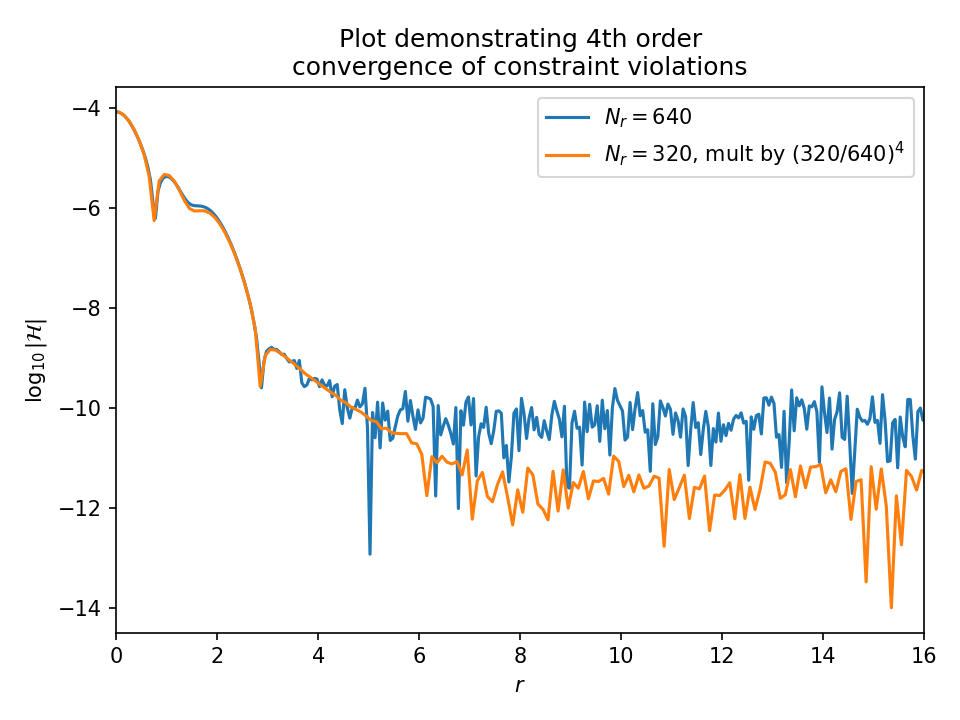

In [53]:
from IPython.display import Image

os.chdir(bssn_dirtree.get_node_str('output'))

cmd.delete_existing_files("out320*.txt")
cmd.Execute("ScalarFieldCollapse_Playground", "320 2 2 "+str(integration_method.cfl_factor),"out320.txt")

os.chdir(os.path.join("../../../"))

outfig = os.path.join(bssn_dirtree.get_node_str('output'),"ScalarFieldCollapse_H_convergence.png")

fig = plt.figure()

r_640,H_640 = np.loadtxt(os.path.join(bssn_dirtree.get_node_str('output'),"out640.txt")).T
r_320,H_320 = np.loadtxt(os.path.join(bssn_dirtree.get_node_str('output'),"out320.txt")).T

plt.title("Plot demonstrating 4th order\nconvergence of constraint violations")
plt.xlabel(r"$r$")
plt.ylabel(r"$\log_{10}|\mathcal{H}|$")
plt.xlim(0,16)
plt.plot(r_640,H_640,label=r"$N_{r} = 640$")
plt.plot(r_320,H_320+4*np.log10(320.0/640.0),label=r"$N_{r} = 320$, mult by $(320/640)^{4}$")
plt.legend()

plt.tight_layout()
plt.savefig(outfig,dpi=150)
plt.close(fig)
Image(outfig)